# Задание 4.5
## Монета до двух одинаковых сторон подряд (несимметричная, $p=0{,}7$)

### Условие:
«Несимметричную» монету бросают, пока она не выпадет дважды одной и той же стороной подряд (вероятность герба $p=0{,}7$). Постройте вероятностную модель и найдите вероятность того, что потребуется: а) чётное число бросаний; б) число бросаний кратно 4.

### Вероятностная модель $(\Omega,\mathbb P)$:
Монету бросают, пока два подряд броска не дадут одну и ту же сторону. Остановка наступает на $n$-м броске ($n\ge2$), если первые $n-1$ бросков **чередуются** ($x_1\ne x_2\ne\dots\ne x_{n-1}$), а $x_n=x_{n-1}$. Такая последовательность однозначно определяется первым броском (Г или Р), поэтому
$$\Omega=\{\,\underbrace{HTHT\dots}_{n-1}\,\text{и повторённый последний символ},\ \ \underbrace{THTH\dots}_{n-1}\text{и повтор}:\ n=2,3,\dots\}=\{HH,\ TT,\ HTT,\ THH,\ HTHH,\ THTT,\dots\}.$$
Ровно **два** исхода имеют длину $n$ (начало с Г и начало с Р). Вероятность исхода — произведение вероятностей бросков (независимость): $\mathbb P(H)=p$, $\mathbb P(T)=q=1-p$.

### Вероятности исходов
Пусть $p=\mathbb P(H)=0{,}7$, $q=\mathbb P(T)=0{,}3$. Посчитаем вероятность исхода длины $n$, который начинается с Г (для начала с Р всё симметрично — меняем $p\leftrightarrow q$). Первые $n-1$ бросков чередуются: Г, Р, Г, Р, …, затем последний бросок повторяет предыдущий.
- **$n=2m$ (чётное):** первые $2m-1$ бросков — $m$ гербов и $m-1$ решек, последний $x_{2m-1}$ — герб, и $x_{2m}$ тоже герб: всего $m+1$ гербов и $m-1$ решек: вероятность $p^{m+1}q^{m-1}$. Для начала с Р: $q^{m+1}p^{m-1}$. Складываем: 
$$\mathbb P(N=2m)=p^{m-1}q^{m-1}(p^2+q^2)=(pq)^{m-1}(p^2+q^2).$$
- **$n=2m+1$ (нечётное):** первые $2m$ бросков — по $m$ гербов и решек, последний из них $x_{2m}$ — решка, и $x_{2m+1}$ — решка: $m$ гербов и $m+1$ решек: $p^mq^{m+1}$; для начала с Р: $q^mp^{m+1}$. Сумма: 
$$\mathbb P(N=2m+1)=(pq)^m(p+q)=(pq)^m,\qquad m\ge1.$$
**Проверка нормировки:** $\displaystyle\sum_{m\ge1}(pq)^{m-1}(p^2+q^2)+\sum_{m\ge1}(pq)^m=\frac{p^2+q^2+pq}{1-pq}=\frac{1-pq}{1-pq}=1$ (так как $p^2+q^2+pq=(p+q)^2-pq=1-pq$).

### Решение:
**а)** $\displaystyle\mathbb P(N\text{ чётно})=\sum_{m\ge1}(pq)^{m-1}(p^2+q^2)=\frac{p^2+q^2}{1-pq}=\frac{0{,}58}{0{,}79}=\frac{58}{79}\approx0{,}7342.$ (При $p=\tfrac12$ получается $\tfrac23$ — как в 4.4.)

**б)** $N=4j$, т. е. $m=2j$: 
$$\mathbb P(4\mid N)=\sum_{j\ge1}(pq)^{2j-1}(p^2+q^2)=\frac{(p^2+q^2)\,pq}{1-(pq)^2}=\frac{0{,}58\cdot0{,}21}{1-0{,}0441}=\frac{1218}{9559}\approx0{,}12742 .$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fractions import Fraction
from math import comb

rng = np.random.default_rng(2024)      # генератор псевдослучайных чисел; фиксированное «зерно» -> результаты воспроизводимы

def running_frequency(hits):
    # Относительная частота p̂_N = N(A)/N для N = 1, 2, ..., len(hits).
    # hits[i] = 1 (True), если в (i+1)-й реализации опыта событие A произошло, иначе 0.
    hits = np.asarray(hits, dtype=float)
    return np.cumsum(hits)/np.arange(1, len(hits) + 1)

def plot_frequency(ax, hits, p_exact, title, label=r'$\hat p_N(A)=N(A)/N$'):
    # График зависимости p̂(A) от числа реализаций N (статистическая устойчивость частоты):
    # синяя линия — относительная частота, красная — точная вероятность,
    # зелёные пунктиры — «коридор» P ± 3·sqrt(P(1−P)/N), в который частота попадает почти всегда.
    n = np.arange(1, len(hits) + 1)
    ph = np.cumsum(hits)/n
    sig = 3*np.sqrt(p_exact*(1 - p_exact)/n)
    ax.plot(n, ph, 'b-', lw=1, label=label)
    ax.axhline(p_exact, color='r', lw=1.5, label=f'P = {p_exact:.6f}')
    ax.plot(n, p_exact + sig, 'g--', lw=0.8, label=r'$P\pm3\sqrt{P(1-P)/N}$'); ax.plot(n, p_exact - sig, 'g--', lw=0.8)
    s = max(10, len(n)//50)                           # первые 2 % точек очень шумные; масштаб по y выбираем по остальным
    lo = min(ph[s:].min(), (p_exact - sig)[s:].min()); hi = max(ph[s:].max(), (p_exact + sig)[s:].max())
    pad = 0.1*(hi - lo); ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(0, len(hits)); ax.grid(alpha=0.3); ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('относительная частота')
    ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def plot_conditional(ax, hits_AB, hits_B, p_exact, title):
    # График условной частоты p̂(A|B) = N(A∩B)/N(B) в зависимости от общего числа реализаций N
    n = np.arange(1, len(hits_B) + 1); cB = np.cumsum(hits_B); cAB = np.cumsum(hits_AB)
    ph = np.where(cB > 0, cAB/np.maximum(cB, 1), np.nan)
    ax.plot(n, ph, 'b-', lw=1, label=r'$\hat p(A|B)=N(A\cap B)/N(B)$'); ax.axhline(p_exact, color='r', lw=1.5, label=f'значение {p_exact:.5f}')
    s = max(10, len(n)//20); v = ph[s:][~np.isnan(ph[s:])]; lo, hi = min(v.min(), p_exact), max(v.max(), p_exact); pad = 0.15*(hi - lo + 1e-9)
    ax.set_ylim(lo - pad, hi + pad); ax.set_xlim(0, len(hits_B)); ax.grid(alpha=0.3)
    ax.set_xlabel('число реализаций опыта N'); ax.set_ylabel('условная частота'); ax.set_title(title, fontsize=10); ax.legend(fontsize=7.5, loc='upper right')

def table(hits, p_exact, Ns=(100, 1000, 10_000, 100_000, 1_000_000)):
    # Печатает оценки p̂ при разных N, отклонение от точного значения и границу 3σ
    hits = np.asarray(hits, dtype=float)
    print('       N        p̂(N)        |p̂ − P|      3σ_N')
    for N in Ns:
        if N <= len(hits):
            ph = hits[:N].mean(); print(f'{N:9d}   {ph:.7f}   {abs(ph - p_exact):.2e}   {3*np.sqrt(p_exact*(1 - p_exact)/N):.2e}')

### Проверка перебором исходов и формул

In [2]:
p = Fraction(7, 10); q = 1 - p

def prob_N(n):
    # P(N = n) по формулам: чётное n=2m: (pq)^(m−1)(p²+q²); нечётное n=2m+1: (pq)^m
    if n % 2 == 0: return (p*q)**(n//2 - 1)*(p*p + q*q)
    return (p*q)**((n - 1)//2)

def enumerate_outcomes(n):
    # Перебором: два исхода длины n (чередование + повтор последнего символа); возвращает сумму их вероятностей
    total = Fraction(0)
    for first in 'HT':
        w = first
        for _ in range(n - 2): w += 'T' if w[-1] == 'H' else 'H'      # n−1 чередующихся символов
        w += w[-1]                                                     # повтор последнего
        pr = Fraction(1)
        for ch in w: pr *= (p if ch == 'H' else q)
        total += pr
    return total

print('n   P(N=n) формула     P(N=n) перебор   совпало')
for n in range(2, 9): print(f'{n}   {float(prob_N(n)):.8f}       {float(enumerate_outcomes(n)):.8f}       {prob_N(n) == enumerate_outcomes(n)}')

P_even = (p*p + q*q)/(1 - p*q)                          # а) замкнутая формула
P_4 = (p*p + q*q)*p*q/(1 - (p*q)**2)                    # б)
print('а) P(чётное) =', P_even, '≈', float(P_even), ';  сумма ряда до n=200:', float(sum(prob_N(n) for n in range(2, 201, 2))))
print('б) P(кратно 4) =', P_4, '≈', float(P_4), ';  сумма ряда до n=200:', float(sum(prob_N(n) for n in range(4, 201, 4))))
print('нормировка: сумма P(N=n), n ≤ 200:', float(sum(prob_N(n) for n in range(2, 201))))

n   P(N=n) формула     P(N=n) перебор   совпало
2   0.58000000       0.58000000       True
3   0.21000000       0.21000000       True
4   0.12180000       0.12180000       True
5   0.04410000       0.04410000       True
6   0.02557800       0.02557800       True
7   0.00926100       0.00926100       True
8   0.00537138       0.00537138       True
а) P(чётное) = 58/79 ≈ 0.7341772151898734 ;  сумма ряда до n=200: 0.7341772151898734
б) P(кратно 4) = 1218/9559 ≈ 0.1274191861073334 ;  сумма ряда до n=200: 0.1274191861073334
нормировка: сумма P(N=n), n ≤ 200: 1.0


### Моделирование $N=300\,000$ реализаций

--- а) чётное: P = 0.7341772
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.7200000   1.42e-02   1.33e-01
     1000   0.7390000   4.82e-03   4.19e-02
    10000   0.7384000   4.22e-03   1.33e-02
   100000   0.7360900   1.91e-03   4.19e-03
   300000   0.7348333   6.56e-04   2.42e-03
--- б) кратно 4: P = 0.1274192
       N        p̂(N)        |p̂ − P|      3σ_N
      100   0.1400000   1.26e-02   1.00e-01
     1000   0.1280000   5.81e-04   3.16e-02
    10000   0.1264000   1.02e-03   1.00e-02
   100000   0.1290000   1.58e-03   3.16e-03
   300000   0.1278033   3.84e-04   1.83e-03


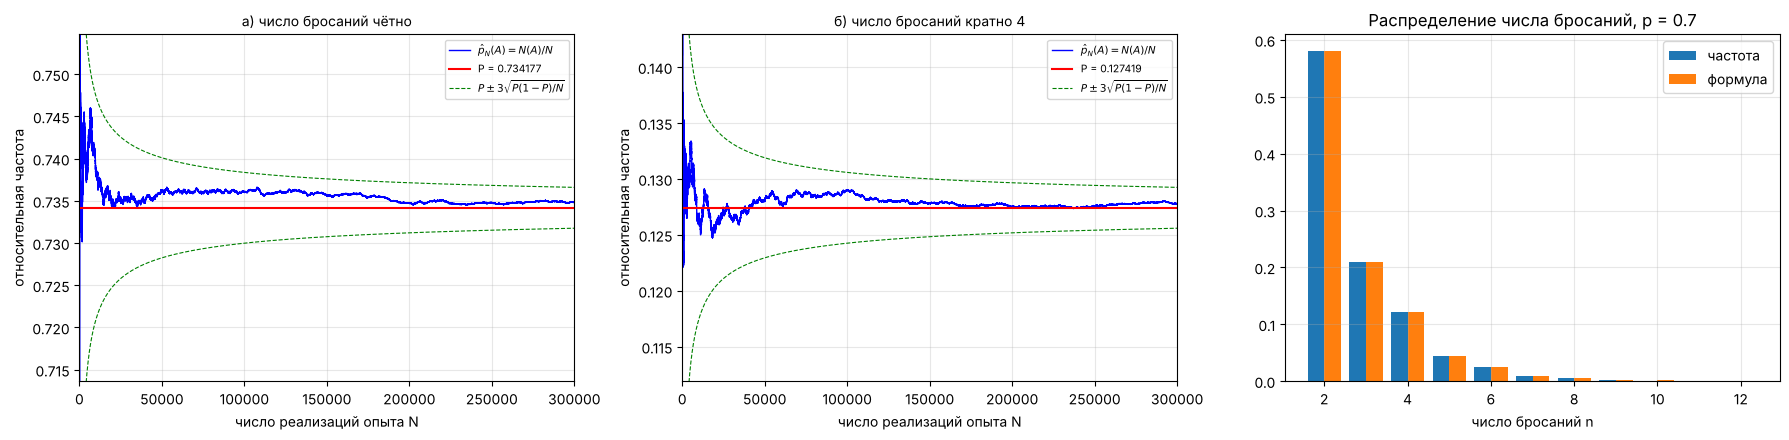

In [3]:
def tosses_until_repeat(p, N, L=80, chunk=50_000):
    out = np.empty(N, dtype=np.int16)
    for s in range(0, N, chunk):
        m = min(chunk, N - s)
        T = rng.random((m, L)) < p                              # True = герб (вероятность 0.7)
        same = T[:, 1:] == T[:, :-1]
        assert same.any(axis=1).all()
        out[s:s + m] = same.argmax(axis=1) + 2
    return out

N = 300_000
n_tosses = tosses_until_repeat(0.7, N)
hit_even, hit_4 = n_tosses % 2 == 0, n_tosses % 4 == 0
for name, h, P in [('а) чётное', hit_even, P_even), ('б) кратно 4', hit_4, P_4)]:
    print(f'--- {name}: P = {float(P):.7f}'); table(h, float(P), Ns=(100, 1000, 10_000, 100_000, 300_000))
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
plot_frequency(axs[0], hit_even, float(P_even), 'а) число бросаний чётно')
plot_frequency(axs[1], hit_4, float(P_4), 'б) число бросаний кратно 4')
k = np.arange(2, 13); axs[2].bar(k - 0.2, [np.mean(n_tosses == i) for i in k], 0.4, label='частота'); axs[2].bar(k + 0.2, [float(prob_N(i)) for i in k], 0.4, label='формула')
axs[2].set_xlabel('число бросаний n'); axs[2].legend(); axs[2].grid(alpha=0.3); axs[2].set_title('Распределение числа бросаний, p = 0.7')
plt.tight_layout(); plt.savefig('task_4_5.png', dpi=130, bbox_inches='tight'); plt.show()

### Ответ:
Модель: $\Omega=\{HH,TT,HTT,THH,HTHH,THTT,\dots\}$; $\mathbb P(N=2m)=(pq)^{m-1}(p^2+q^2)$, $\mathbb P(N=2m+1)=(pq)^m$ при $p=0{,}7$, $q=0{,}3$.
а) $\mathbb P(N\ \text{чётно})=\dfrac{58}{79}\approx0{,}7342$; б) $\mathbb P(4\mid N)=\dfrac{1218}{9559}\approx0{,}1274$.